# Практика 1. S3: хранилище для данных и моделей

**Перед началом:** этот файл только для чтения и общий для всей группы.
Сохраните свою копию: **File → Save Notebook As…** →
`work/students/<ваше_имя>/01_s3.ipynb` и работайте в ней.

План:
1. Установка библиотек
2. Подключение к S3
3. Свой бакет
4. Загрузка файлов в S3
5. Просмотр содержимого
6. Скачивание файлов
7. Таблицы pandas и модели в S3
8. Копирование, удаление, ссылка для скачивания
9. **Задачи**
**Выполненное решение.** По умолчанию `LAB_MODE=local`: S3 эмулируется Moto в памяти, без учебного сервера. Для сервера установите `LAB_MODE=remote`, `S3_USER`, `S3_PASSWORD`, `S3_ENDPOINT_URL`; для внешних ссылок при необходимости `S3_PUBLIC_ENDPOINT_URL`. Перезапуск ядра очищает локальный S3.


## 1. Установка библиотек

- **boto3** — клиент S3: один и тот же API для локальной проверки и учебного сервера.
- **moto** — эмулятор S3 в памяти для локального режима.
- **pandas**, **pyarrow**, **matplotlib**, **scikit-learn** — таблицы, Parquet, графики и модели.

Ячейка ниже устанавливает необходимые библиотеки в интерпретатор текущего ядра.

In [1]:
%pip install -q boto3 pandas pyarrow matplotlib scikit-learn "moto[s3]"


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: C:\Users\Enot\PycharmProjects\ML_lab1n2\.venv\Scripts\python.exe -m pip install --upgrade pip


In [2]:
import boto3
print("boto3", boto3.__version__)

boto3 1.44.2


## 2. Подключение к S3

Чтобы подключиться, нужны три вещи:

| Что | Где взять |
|---|---|
| адрес хранилища (`endpoint_url`) | внутри сервера `http://s3:9000`, снаружи `http://10.162.1.86:9000` |
| логин (`aws_access_key_id`) | ваш логин S3: `user1` … `user30` (выдаёт преподаватель) |
| пароль (`aws_secret_access_key`) | выдаёт преподаватель |

**Пароль никогда не пишем в код** — код попадает в Git и в чужие руки. Вводим его через `getpass`:
он спрашивается при запуске ячейки и нигде не сохраняется.

In [3]:
import os
from pathlib import Path
from getpass import getpass

LAB_MODE = os.environ.get("LAB_MODE", "local").lower()
if LAB_MODE not in {"local", "remote"}:
    raise ValueError("LAB_MODE должен быть local или remote")
S3_URL = os.environ.get("S3_ENDPOINT_URL", "http://10.162.1.86:9000")
LOCAL_DIR = Path("lab_artifacts/s3")
LOCAL_DIR.mkdir(parents=True, exist_ok=True)
print("Режим:", LAB_MODE)
print("S3:", "эмулятор Moto в памяти" if LAB_MODE == "local" else S3_URL)


Режим: local
S3: эмулятор Moto в памяти


In [4]:
from botocore.config import Config

if LAB_MODE == "local":
    from moto import mock_aws
    # При повторном выполнении настройки завершаем предыдущий эмулятор.
    if "s3_mock" in globals():
        s3_mock.stop()
    s3_mock = mock_aws()
    s3_mock.start()
    S3_USER, S3_PASSWORD = "local-student", "local-test-secret"
    s3 = boto3.client("s3", region_name="us-east-1",
                      aws_access_key_id=S3_USER, aws_secret_access_key=S3_PASSWORD,
                      config=Config(signature_version="s3v4"))
else:
    S3_USER = os.environ.get("S3_USER") or input("Логин S3 (userN): ").strip()
    S3_PASSWORD = os.environ.get("S3_PASSWORD") or getpass(f"Пароль S3 для {S3_USER}: ")
    s3 = boto3.client("s3", endpoint_url=S3_URL, region_name="us-east-1",
                      aws_access_key_id=S3_USER, aws_secret_access_key=S3_PASSWORD,
                      config=Config(signature_version="s3v4", s3={"addressing_style": "path"}))
for b in s3.list_buckets()["Buckets"]:
    print(b["Name"], b["CreationDate"].date())


## 3. Свой бакет

Бакет — большой контейнер с уникальным именем. У каждого студента свой: **имя бакета = ваш логин** (`user7` → бакет `user7`).

Бакет уже создан для вас заранее. Права настроены так, что вы видите и можете делать всё **только в своём бакете**.
Создать бакет с другим именем или заглянуть в чужой нельзя — сервер ответит `AccessDenied`. Это и есть разграничение доступа в S3.

In [5]:
BUCKET = S3_USER
print("мой бакет:", BUCKET)

мой бакет: local-student


In [6]:
from botocore.exceptions import ClientError

def bucket_exists(name: str) -> bool:
    try:
        s3.head_bucket(Bucket=name)
        return True
    except ClientError as exc:
        if exc.response["Error"]["Code"] in {"404", "NoSuchBucket", "NotFound"}:
            return False
        raise  # Ошибку прав доступа нельзя принимать за отсутствие бакета.

if not bucket_exists(BUCKET):
    s3.create_bucket(Bucket=BUCKET)
    print("создан бакет", BUCKET)
else:
    print("бакет уже есть:", BUCKET)


создан бакет local-student


In [7]:
if LAB_MODE == "local":
    print("Права учебного сервера локально не проверяются: Moto не повторяет его политику доступа.")
else:
    try:
        s3.list_objects_v2(Bucket="students")
        print("Доступ к students разрешён текущей политикой сервера")
    except ClientError as exc:
        print("чужой бакет:", exc.response["Error"]["Code"])


Права учебного сервера локально не проверяются: Moto не повторяет его политику доступа.


## 4. Загрузка файлов в S3

Три способа:

| Метод | Когда |
|---|---|
| `upload_file(путь, бакет, ключ)` | файл уже лежит на диске |
| `put_object(Bucket, Key, Body)` | данные в памяти: строка или байты |
| `upload_fileobj(файл, бакет, ключ)` | открытый файл или поток |

**Ключ** — полное имя объекта. Слеши в ключе выглядят как папки, но это просто часть имени.

In [8]:
hello_path = LOCAL_DIR / "hello.txt"
hello_path.write_text("Привет, S3!\n", encoding="utf-8")
s3.upload_file(str(hello_path), BUCKET, "docs/hello.txt")
print("загружен docs/hello.txt")


загружен docs/hello.txt


In [9]:
# 4.2 строка из памяти, без файла на диске
s3.put_object(Bucket=BUCKET, Key="docs/note.txt", Body="Заметка из памяти".encode("utf-8"))
print("загружен docs/note.txt")

загружен docs/note.txt


In [10]:
# 4.3 таблица pandas -> CSV в S3
import pandas as pd
from sklearn.datasets import load_wine

wine = load_wine(as_frame=True).frame
s3.put_object(Bucket=BUCKET, Key="data/raw/wine.csv", Body=wine.to_csv(index=False))
print("загружен data/raw/wine.csv:", wine.shape)

загружен data/raw/wine.csv: (178, 14)


In [11]:
# 4.4 картинка matplotlib -> PNG в S3 (через память, без диска)
import io
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 3))
wine["alcohol"].hist(ax=ax, bins=20)
ax.set_title("Алкоголь в винах")

buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=100)
plt.close(fig)
s3.put_object(Bucket=BUCKET, Key="images/alcohol.png", Body=buf.getvalue(), ContentType="image/png")
print("загружен images/alcohol.png,", len(buf.getvalue()), "байт")

загружен images/alcohol.png, 13753 байт


## 5. Что лежит в бакете

`list_objects_v2` возвращает до 1000 объектов. `Prefix` — показать только ключи, начинающиеся с этой строки («папка»).

In [12]:
def ls(prefix: str = ""):
    for page in s3.get_paginator("list_objects_v2").paginate(Bucket=BUCKET, Prefix=prefix):
        for obj in page.get("Contents", []):
            print(f'{obj["Key"]:<40} {obj["Size"]:>8} байт   {obj["LastModified"]:%Y-%m-%d %H:%M}')

ls()


data/raw/wine.csv                           12440 байт   2026-11-12 21:52
docs/hello.txt                                 19 байт   2026-11-12 21:52
docs/note.txt                                  32 байт   2026-11-12 21:52
images/alcohol.png                          13753 байт   2026-11-12 21:52


In [13]:
ls("docs/")   # только «папка» docs

docs/hello.txt                                 19 байт   2026-11-12 21:52
docs/note.txt                                  32 байт   2026-11-12 21:52


In [14]:
# метаданные одного объекта, без скачивания
meta = s3.head_object(Bucket=BUCKET, Key="images/alcohol.png")
print(meta["ContentLength"], "байт,", meta["ContentType"])

13753 байт, image/png


## 6. Скачивание

| Метод | Результат |
|---|---|
| `download_file(бакет, ключ, путь)` | файл на диске |
| `get_object(Bucket, Key)["Body"].read()` | байты в памяти |

In [15]:
hello_downloaded = LOCAL_DIR / "hello_downloaded.txt"
s3.download_file(BUCKET, "docs/hello.txt", str(hello_downloaded))
print(hello_downloaded.read_text(encoding="utf-8"))


Привет, S3!



In [16]:
# 6.2 в память
body = s3.get_object(Bucket=BUCKET, Key="docs/note.txt")["Body"].read()
print(body.decode("utf-8"))

Заметка из памяти


In [17]:
# 6.3 CSV из S3 сразу в pandas
body = s3.get_object(Bucket=BUCKET, Key="data/raw/wine.csv")["Body"].read()
df = pd.read_csv(io.BytesIO(body))
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


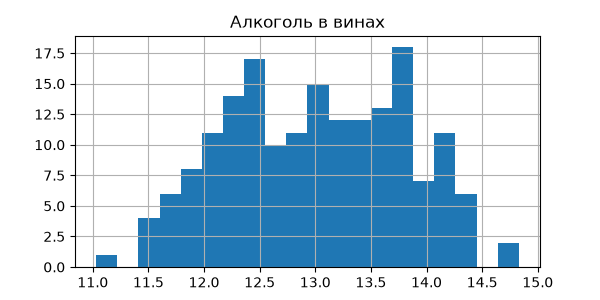

In [18]:
# 6.4 картинку из S3 — показать в ноутбуке
from IPython.display import Image
Image(s3.get_object(Bucket=BUCKET, Key="images/alcohol.png")["Body"].read())

## 7. Parquet и модели в S3

### Зачем это нужно
В ML-конвейере данные сохраняют **много раз**: сырые → очищенные → train/test → прогнозы.
Если каждый раз сохранять в CSV, возникают три проблемы:

1. **Размер.** CSV — это текст: число `300.25` занимает 6 байт, в parquet — меньше и ещё сжимается.
2. **Скорость.** CSV нужно разбирать построчно, parquet читается почти сразу.
3. **Типы теряются.** Сохранили дату в CSV — прочитали обратно **строку**. Parquet помнит, что это дата.

**Parquet** — формат таблиц, который решает все три проблемы. Поэтому в ML его используют почти везде
(в наших DAG-ах train/test тоже лежат в `.parquet`).

### Что сделаем
- **7.1** — сравним CSV и parquet на таблице продаж в **миллион строк** (как в примере с магазином из лекции);
- **7.2** — научимся класть таблицу в S3 в parquet и читать обратно: это приём, который вы будете использовать в Airflow;
- **7.3** — так же сохраним в S3 **модель**.

In [19]:
# 7.1 CSV против parquet на большой таблице (всё в памяти, в S3 пока не пишем)
import time
import numpy as np

n = 1_000_000
rng = np.random.default_rng(42)
sales = pd.DataFrame({
    "time": pd.date_range("2026-01-01", periods=n, freq="min"),   # дата и время продажи
    "store": rng.choice(["Москва", "Казань", "Сочи"], n),
    "product_id": rng.integers(1, 5000, n),
    "price": rng.normal(300, 50, n).round(2),
    "sold": rng.integers(0, 20, n),
})

csv_bytes = sales.to_csv(index=False).encode()        # таблица -> CSV (байты)
pq_buf = io.BytesIO()
sales.to_parquet(pq_buf, index=False)                  # таблица -> parquet (байты)
pq_bytes = pq_buf.getvalue()

t = time.time(); from_csv = pd.read_csv(io.BytesIO(csv_bytes)); t_csv = time.time() - t
t = time.time(); from_pq = pd.read_parquet(io.BytesIO(pq_bytes)); t_pq = time.time() - t

print(f"Размер:  CSV {len(csv_bytes)/1e6:.1f} МБ   parquet {len(pq_bytes)/1e6:.1f} МБ   (в {len(csv_bytes)/len(pq_bytes):.1f} раза меньше)")
print(f"Чтение:  CSV {t_csv:.2f} с     parquet {t_pq:.2f} с")
print("Тип колонки time после CSV:    ", from_csv["time"].dtype, " <- строка, дату надо разбирать заново")
print("Тип колонки time после parquet:", from_pq["time"].dtype)

Размер:  CSV 46.8 МБ   parquet 10.9 МБ   (в 4.3 раза меньше)
Чтение:  CSV 0.10 с     parquet 0.04 с
Тип колонки time после CSV:     str  <- строка, дату надо разбирать заново
Тип колонки time после parquet: datetime64[us]


**Что видно:** parquet в несколько раз меньше, читается во много раз быстрее, и дата осталась датой.
Для ML это значит: меньше места в S3, быстрее задачи Airflow и нет ошибок из-за «испорченных» типов.

Ещё один плюс — можно прочитать **только нужные колонки**, не загружая всю таблицу:

In [20]:
t = time.time()
only_sold = pd.read_parquet(io.BytesIO(pq_bytes), columns=["sold"])
print(f"одна колонка из миллиона строк: {time.time() - t:.3f} с")

одна колонка из миллиона строк: 0.003 с


> На маленькой таблице (150–200 строк, как Iris или Wine) parquet может оказаться даже **больше** CSV:
> в файле есть служебная информация о колонках. Выигрыш появляется на больших данных — а в реальных задачах они большие.

### 7.2 Таблица в S3 в формате parquet и обратно
Схема всегда одна и та же, её стоит запомнить:

**сохранить:** DataFrame → `to_parquet` в буфер памяти → `put_object`<br>
**прочитать:** `get_object` → байты → `read_parquet`

In [21]:
# сохранить: DataFrame -> parquet в памяти -> S3
buf = io.BytesIO()
sales.to_parquet(buf, index=False)
s3.put_object(Bucket=BUCKET, Key="data/processed/sales.parquet", Body=buf.getvalue())

# прочитать: S3 -> байты -> DataFrame
body = s3.get_object(Bucket=BUCKET, Key="data/processed/sales.parquet")["Body"].read()
sales_back = pd.read_parquet(io.BytesIO(body))

print("в S3:", s3.head_object(Bucket=BUCKET, Key="data/processed/sales.parquet")["ContentLength"] // 1_000_000, "МБ")
print("прочитали", sales_back.shape, "| совпадает с исходной:", sales_back.equals(sales))

в S3: 10 МБ
прочитали (1000000, 5) | совпадает с исходной: True


### 7.3 Модель в S3
Модель sklearn — это объект Python, а S3 хранит байты. `joblib.dump` превращает модель в байты,
`joblib.load` — обратно. Так модель, обученную в одной задаче Airflow, загружает следующая задача
или сервис прогнозов на другом компьютере.

In [22]:
import joblib
from sklearn.linear_model import LogisticRegression

X, y = wine.drop(columns="target"), wine["target"]
model = LogisticRegression(max_iter=5000).fit(X, y)

buf = io.BytesIO()
joblib.dump(model, buf)                                         # модель -> байты
s3.put_object(Bucket=BUCKET, Key="models/logreg.joblib", Body=buf.getvalue())

body = s3.get_object(Bucket=BUCKET, Key="models/logreg.joblib")["Body"].read()
loaded = joblib.load(io.BytesIO(body))                          # байты -> модель
print("прогноз загруженной модели:", loaded.predict(X.head(5)))

прогноз загруженной модели: [0 0 0 0 0]


C:\Users\Enot\PycharmProjects\ML_lab1n2\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 5000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=5000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## 8. Копирование, удаление, ссылка для скачивания

In [23]:
# 8.1 копия внутри S3 (данные не проходят через ваш компьютер)
s3.copy_object(Bucket=BUCKET, Key="backup/wine.csv",
               CopySource={"Bucket": BUCKET, "Key": "data/raw/wine.csv"})
ls("backup/")

backup/wine.csv                             12440 байт   2026-11-12 21:52


In [24]:
# 8.2 удаление
s3.delete_object(Bucket=BUCKET, Key="backup/wine.csv")
ls("backup/")
print("после удаления в backup/ пусто")

после удаления в backup/ пусто


In [25]:
public = s3 if LAB_MODE == "local" else boto3.client(
    "s3", endpoint_url=os.environ.get("S3_PUBLIC_ENDPOINT_URL", S3_URL),
    region_name="us-east-1", aws_access_key_id=S3_USER, aws_secret_access_key=S3_PASSWORD,
    config=Config(signature_version="s3v4", s3={"addressing_style": "path"}))
url = public.generate_presigned_url(
    "get_object", Params={"Bucket": BUCKET, "Key": "images/alcohol.png"}, ExpiresIn=600)
if LAB_MODE == "remote":
    from IPython.display import HTML, display
    display(HTML(f'<a href="{url}" target="_blank">Скачать график (10 минут)</a>'))
else:
    print("Подпись сформирована на 600 секунд. Moto работает в памяти: HTTP-ссылка недоступна.")


Подпись сформирована на 600 секунд. Moto работает в памяти: HTTP-ссылка недоступна.


## Шпаргалка

| Действие | Команда |
|---|---|
| подключиться | `s3 = boto3.client("s3", endpoint_url=..., aws_access_key_id=..., aws_secret_access_key=...)` |
| бакеты | `s3.list_buckets()`, `s3.create_bucket(Bucket=b)` |
| загрузить | `s3.upload_file(путь, b, key)`, `s3.put_object(Bucket=b, Key=key, Body=...)` |
| список | `s3.list_objects_v2(Bucket=b, Prefix="docs/")` |
| скачать | `s3.download_file(b, key, путь)`, `s3.get_object(Bucket=b, Key=key)["Body"].read()` |
| метаданные | `s3.head_object(Bucket=b, Key=key)` |
| копировать / удалить | `s3.copy_object(...)`, `s3.delete_object(Bucket=b, Key=key)` |
| ссылка | `s3.generate_presigned_url("get_object", Params=..., ExpiresIn=600)` |

---
# 9. Задачи

Все задачи — в **своём бакете** `BUCKET`. Проверяйте результат через `ls()` и в веб-консоли S3.

### Задача 1. Iris в S3
Загрузите датасет Iris (`sklearn.datasets.load_iris(as_frame=True).frame`) в свой бакет как CSV
по ключу `data/raw/iris.csv`. Выведите содержимое «папки» `data/raw/`.

In [26]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True).frame
s3.put_object(Bucket=BUCKET, Key="data/raw/iris.csv",
              Body=iris.to_csv(index=False).encode("utf-8"), ContentType="text/csv")
ls("data/raw/")


data/raw/iris.csv                            2928 байт   2026-11-12 21:52
data/raw/wine.csv                           12440 байт   2026-11-12 21:52


### Задача 2. Несколько файлов в цикле
Создайте 3 текстовых отчёта `reports/report_1.txt` … `reports/report_3.txt`
(в каждом — строка «Отчёт номер N»). Потом одной командой получите список `reports/`
и посчитайте **общий размер** этих файлов в байтах.

In [27]:
report_keys = [f"reports/report_{n}.txt" for n in range(1, 4)]
for n, key in enumerate(report_keys, start=1):
    s3.put_object(Bucket=BUCKET, Key=key, Body=f"Отчёт номер {n}".encode("utf-8"),
                  ContentType="text/plain; charset=utf-8")

reports = s3.list_objects_v2(Bucket=BUCKET, Prefix="reports/").get("Contents", [])
own_reports = [obj for obj in reports if obj["Key"] in report_keys]
for obj in own_reports:
    print(obj["Key"], obj["Size"], "байт")
print("Общий размер трёх отчётов:", sum(obj["Size"] for obj in own_reports), "байт")
assert len(own_reports) == 3


reports/report_1.txt 23 байт
reports/report_2.txt 23 байт
reports/report_3.txt 23 байт
Общий размер трёх отчётов: 69 байт


### Задача 3. Скачать и проверить
Скачайте `data/raw/iris.csv` **на диск** в файл `iris_local.csv`, прочитайте его pandas
и проверьте, что строк столько же, сколько в исходном датасете (150).

In [28]:
iris_path = LOCAL_DIR / "iris_local.csv"
s3.download_file(BUCKET, "data/raw/iris.csv", str(iris_path))
iris_local = pd.read_csv(iris_path)
assert len(iris_local) == len(iris) == 150
print(f"Скачано в {iris_path}: {len(iris_local)} строк — проверка пройдена")
display(iris_local.head())


Скачано в lab_artifacts\s3\iris_local.csv: 150 строк — проверка пройдена


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


### Задача 4. Parquet туда и обратно
Сохраните Iris в S3 в формате **parquet** по ключу `data/processed/iris.parquet`,
прочитайте обратно в DataFrame и проверьте `.equals()`. Сравните размеры CSV и parquet (`head_object`).
Какой файл меньше и почему? Что изменится для таблицы в миллион строк?

In [29]:
parquet_buffer = io.BytesIO()
iris.to_parquet(parquet_buffer, index=False)
s3.put_object(Bucket=BUCKET, Key="data/processed/iris.parquet", Body=parquet_buffer.getvalue())
iris_back = pd.read_parquet(io.BytesIO(
    s3.get_object(Bucket=BUCKET, Key="data/processed/iris.parquet")["Body"].read()))
assert iris_back.equals(iris)
print("DataFrame.equals:", iris_back.equals(iris))
iris_sizes = {fmt: s3.head_object(Bucket=BUCKET, Key=key)["ContentLength"] for fmt, key in {
    "CSV": "data/raw/iris.csv", "Parquet": "data/processed/iris.parquet"}.items()}
print("Размеры, байт:", iris_sizes, "| меньше:", min(iris_sizes, key=iris_sizes.get))
print("На 150 строках заметны накладные расходы Parquet: схема и метаданные колонок.")
print("На миллионе строк обычно выигрывает Parquet за счёт сжатия и хранения по колонкам;")
print("это подтверждает измерение таблицы sales в разделе 7.1. Типы данных сохраняются.")


DataFrame.equals: True
Размеры, байт: {'CSV': 2928, 'Parquet': 4760} | меньше: CSV
На 150 строках заметны накладные расходы Parquet: схема и метаданные колонок.
На миллионе строк обычно выигрывает Parquet за счёт сжатия и хранения по колонкам;
это подтверждает измерение таблицы sales в разделе 7.1. Типы данных сохраняются.


### Задача 5. График и ссылка
Постройте диаграмму рассеяния Iris (`petal length (cm)` против `petal width (cm)`, цвет — `target`),
сохраните её в S3 как `images/iris_scatter.png` **без записи на диск** и получите ссылку на 10 минут.
Откройте ссылку в браузере.

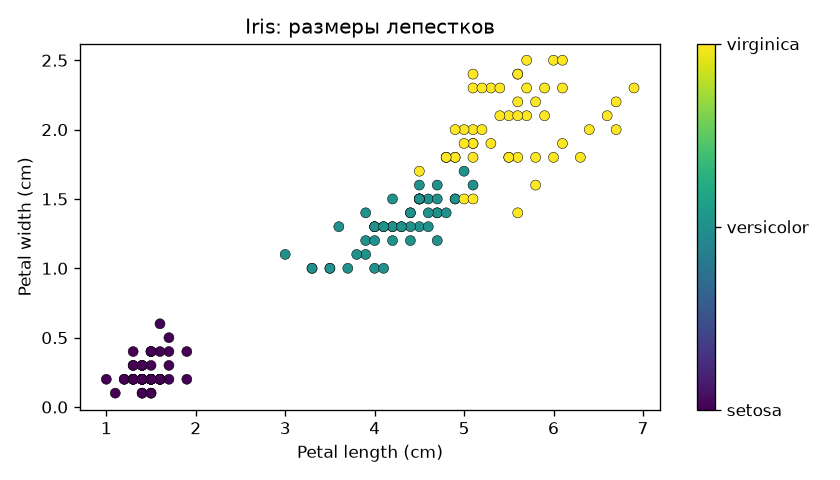

Локально график прочитан из Moto и показан выше. Подписанная ссылка создана,
но для открытия в браузере нужен HTTP-сервер S3 (режим remote).


In [30]:
from IPython.display import Image, HTML, display

fig, ax = plt.subplots(figsize=(7, 4))
points = ax.scatter(iris["petal length (cm)"], iris["petal width (cm)"],
                    c=iris["target"], cmap="viridis", edgecolors="black", linewidths=0.3)
ax.set(xlabel="Petal length (cm)", ylabel="Petal width (cm)", title="Iris: размеры лепестков")
colorbar = fig.colorbar(points, ax=ax, ticks=[0, 1, 2])
colorbar.ax.set_yticklabels(load_iris().target_names)
fig.tight_layout()
image_buffer = io.BytesIO()
fig.savefig(image_buffer, format="png", dpi=120)
plt.close(fig)
s3.put_object(Bucket=BUCKET, Key="images/iris_scatter.png",
              Body=image_buffer.getvalue(), ContentType="image/png")
iris_url = public.generate_presigned_url(
    "get_object", Params={"Bucket": BUCKET, "Key": "images/iris_scatter.png"}, ExpiresIn=600)
display(Image(s3.get_object(Bucket=BUCKET, Key="images/iris_scatter.png")["Body"].read()))
if LAB_MODE == "remote":
    display(HTML(f'<a href="{iris_url}" target="_blank">Открыть график (10 минут)</a>'))
else:
    print("Локально график прочитан из Moto и показан выше. Подписанная ссылка создана,")
    print("но для открытия в браузере нужен HTTP-сервер S3 (режим remote).")


### Задача 6. Модель в S3
Обучите `RandomForestClassifier(random_state=42)` на Iris, сохраните модель в `models/iris_rf.joblib`,
загрузите её обратно и посчитайте accuracy загруженной модели на всём датасете.

In [31]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

Xi, yi = iris.drop(columns="target"), iris["target"]
iris_rf = RandomForestClassifier(random_state=42).fit(Xi, yi)
model_buffer = io.BytesIO()
joblib.dump(iris_rf, model_buffer)
s3.put_object(Bucket=BUCKET, Key="models/iris_rf.joblib", Body=model_buffer.getvalue())
# Загружаем только собственную модель: joblib использует pickle.
restored_rf = joblib.load(io.BytesIO(
    s3.get_object(Bucket=BUCKET, Key="models/iris_rf.joblib")["Body"].read()))
np.testing.assert_array_equal(restored_rf.predict(Xi), iris_rf.predict(Xi))
iris_accuracy = accuracy_score(yi, restored_rf.predict(Xi))
print(f"Accuracy загруженной модели на всём Iris: {iris_accuracy:.4f}")
print("Это оценка на обучающих данных, а не оценка обобщения.")


Accuracy загруженной модели на всём Iris: 1.0000
Это оценка на обучающих данных, а не оценка обобщения.


### Задача 7 (со звёздочкой). Резервная копия «папки»
Напишите функцию `backup(prefix)`, которая копирует **все** объекты с ключами на `prefix`
в `backup/<prefix>…` через `copy_object`. Сделайте резервную копию `reports/`,
затем удалите оригиналы из `reports/` и покажите, что копии на месте.

In [32]:
def backup(prefix: str):
    if not prefix or prefix.startswith("backup/"):
        raise ValueError("Нужен непустой исходный префикс вне backup/")
    # Собираем ключи до копирования, чтобы новые объекты не попали в обход.
    keys = [obj["Key"]
            for page in s3.get_paginator("list_objects_v2").paginate(Bucket=BUCKET, Prefix=prefix)
            for obj in page.get("Contents", [])]
    for key in keys:
        s3.copy_object(Bucket=BUCKET, Key=f"backup/{key}",
                       CopySource={"Bucket": BUCKET, "Key": key})
    return keys

copied_keys = backup("reports/")
for key in copied_keys:
    original = s3.get_object(Bucket=BUCKET, Key=key)["Body"].read()
    copied = s3.get_object(Bucket=BUCKET, Key=f"backup/{key}")["Body"].read()
    assert original == copied
# Удаляем только созданные в задаче отчёты, сохраняя чужие файлы при работе с сервером.
for key in report_keys:
    assert key in copied_keys
    s3.delete_object(Bucket=BUCKET, Key=key)
remaining = [obj["Key"]
             for page in s3.get_paginator("list_objects_v2").paginate(Bucket=BUCKET, Prefix="reports/")
             for obj in page.get("Contents", [])]
assert not set(report_keys) & set(remaining)
print("Оригиналы трёх отчётов удалены; резервные копии проверены:")
ls("backup/reports/")


Оригиналы трёх отчётов удалены; резервные копии проверены:


backup/reports/report_1.txt                    23 байт   2026-11-12 21:52
backup/reports/report_2.txt                    23 байт   2026-11-12 21:52
backup/reports/report_3.txt                    23 байт   2026-11-12 21:52


---
**Готово?** Откройте веб-консоль S3 (`http://10.162.1.86:9001/rustfs/console/index.html`),
войдите **своим логином и паролем S3** и посмотрите файлы своего бакета глазами. Дальше — Airflow: те же операции, но через `S3Hook`
и по расписанию.